# Task 3B & Task E — Temporal Association Analysis
**Project:** Conference Popularity and Association Pattern Mining Using DBLP Dataset (2015–2025)  
**Kelompok:** 11  
**Penanggung Jawab:** Anggota 3 (Temporal Analyst & Integration Lead)

---
### Tujuan Analisis:
1. **Task 3B (Author-Year Transactional Database):** Membangun representasi transaksi di mana 1 transaksi = kombinasi 1 author pada 1 tahun tertentu, serta membandingkannya secara analitis dengan *Author-Based* (Task 3A).
2. **Task E (Temporal Association Analysis):** Menerapkan Frequent Pattern Mining & Association Rules pada **4 periode waktu**:
   - **Periode 1: 2015–2017**
   - **Periode 2: 2018–2020**
   - **Periode 3: 2021–2023**
   - **Periode 4: 2024–2025**
3. **Sintesis Lintas Periode:** Mengidentifikasi **Pola Bertahan (Stable Patterns)** dan **Pergeseran Tren Riset (Shifting Trends)**.

## 0. Import Library & Persiapan Lingkungan

In [1]:
import os
import sys
import gc
import time
import json
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sys.path.append(os.path.abspath('../src'))
from data_loader import build_venue_label_map
from role3_temporal import (
    construct_author_year_transactions,
    run_temporal_mining,
    PERIODS,
    OUTPUT_DIR,
    DATA_PATH,
)

sns.set_theme(style='whitegrid', font_scale=1.05)
plt.rcParams['figure.dpi'] = 130
print('Seluruh modul berhasil diimpor!')

Seluruh modul berhasil diimpor!


## 1. Memuat Dataset Bersih DBLP (`clean_inproceedings.parquet`)

In [2]:
t0 = time.perf_counter()

df = pd.read_parquet(DATA_PATH, columns=['author_id', 'year', 'venue_key', 'venue_name'])
print(f'Dataset berhasil dimuat: {len(df):,} publikasi ({time.perf_counter() - t0:.2f} detik).')
print(f'Rentang tahun: {df["year"].min()} - {df["year"].max()}')
df.head()

Dataset berhasil dimuat: 1,899,038 publikasi (5.93 detik).
Rentang tahun: 2015 - 2025


,author_id,year,venue_key,venue_name
0,"[Lucas Roquet, Fernando Fernandes dos Santos, ...",2024,dac,DAC
1,"[Fangxin Liu, Wenbo Zhao 0005, Zongwu Wang, Yo...",2022,dac,DAC
2,"[Sunwoo Ahn, Hayoon Yi, Younghan Lee, Whoi Ree...",2020,dac,DAC
3,"[Chanwoo Park, Junghwan Park, Premkumar Vincen...",2024,dac,DAC
4,"[Yuan Pu 0001, Fangzhou Liu, Yu Zhang 0189, Zh...",2024,dac,DAC


## 2. Task 3B Konstruksi Author-Year-Based Transactional Database

Pada representasi ini:
- **Satu transaksi** = kombinasi unik satu author_id dan satu year.
- **Item** = daftar venue_key unik tempat author tersebut mempublikasikan paper pada tahun tersebut.

In [3]:
_, venue_display_map = build_venue_label_map(df)
task3b_res = construct_author_year_transactions(df, venue_display_map, OUTPUT_DIR)
display(task3b_res['stats_df'])
display(task3b_res['dist_bucket'])


TASK 3B: KONSTRUKSI AUTHOR-YEAR TRANSACTIONAL DATABASE (Vectorized)
  [Bit-Packing] 7,428,192 entri author-paper -> 6,139,541 tripel (author, year, venue) unik
                             Metrik              Nilai
      Total Transaksi (Author-Year)          3,895,225
           Total Item Unik (Venues)              4,232
Total Pasangan (Author-Year, Venue)          6,139,541
      Rata-rata Venue per Transaksi              1.576
         Median Venue per Transaksi                1.0
   Persentil 95 Venue per Transaksi                4.0
   Persentil 99 Venue per Transaksi                7.0
       Maksimum Venue per Transaksi                 92
        Transaksi 1 Venue (len = 1) 2,784,636 (71.49%)
   Transaksi Multi-Venue (len >= 2) 1,110,589 (28.51%)
    Transaksi >= 3 Venue (len >= 3)   485,151 (12.46%)
  [Task 3B] Selesai dalam 14.22 detik. Berkas CSV tersimpan.


,Metrik,Nilai
0,Total Transaksi (Author-Year),"3,895,225"
1,Total Item Unik (Venues),"4,232"
2,"Total Pasangan (Author-Year, Venue)","6,139,541"
3,Rata-rata Venue per Transaksi,1.576
4,Median Venue per Transaksi,1.0
5,Persentil 95 Venue per Transaksi,4.0
6,Persentil 99 Venue per Transaksi,7.0
7,Maksimum Venue per Transaksi,92
8,Transaksi 1 Venue (len = 1),"2,784,636 (71.49%)"
9,Transaksi Multi-Venue (len >= 2),"1,110,589 (28.51%)"


,bucket,count,pct
0,1,2784636,71.49
1,2,625438,16.06
2,3,237757,6.10
3,4,108587,2.79
4,5,55972,1.44
5,6-10,71587,1.84
6,>10,11248,0.29


### 2.0 Distribusi Jumlah Item per Transaksi (Author-Year)
Histogram memakai sumbu-y logaritmik karena mayoritas transaksi hanya berisi 1 konferensi.

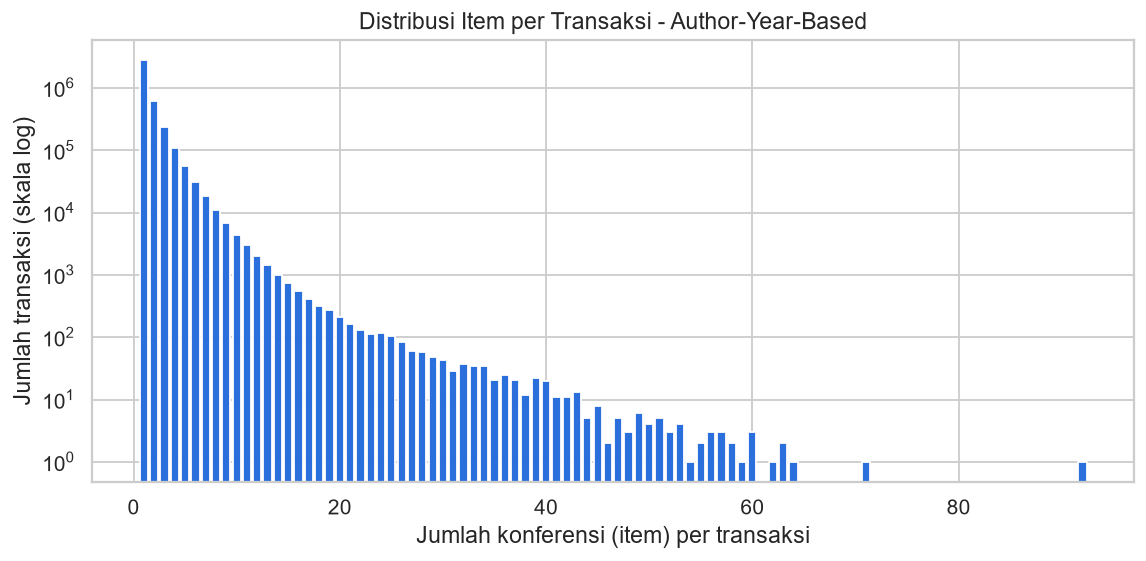

In [4]:
d = task3b_res['dist_exact']
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.bar(d['jumlah_item'], d['jumlah_transaksi'], color='#2a6fdb')
ax.set_yscale('log')
ax.set_xlabel('Jumlah konferensi (item) per transaksi')
ax.set_ylabel('Jumlah transaksi (skala log)')
ax.set_title('Distribusi Item per Transaksi - Author-Year-Based')
plt.tight_layout(); plt.show()

### 2.0b Cross-check dengan Role 2
Jumlah transaksi dan distribusi 3B harus identik dengan kolom Author-Year-Based milik Role 2.

In [5]:
r2_path = OUTPUT_DIR.parent / 'role2' / 'task3_transaction_stats.csv'
if r2_path.is_file():
    r2 = pd.read_csv(r2_path)
    display(r2)
    n_r2 = int(str(r2.loc[r2['Metrik'].str.contains('Jumlah Transaksi'), 'Author-Year-Based'].iloc[0]).replace(',', ''))
    print('n_tx Role 3 =', task3b_res['n_tx'], '| n_tx Role 2 =', n_r2, '| COCOK' if n_r2 == task3b_res['n_tx'] else '| BEDA!')
else:
    print('File Role 2 tidak ditemukan di', r2_path, '- salin folder output/role2 ke sini lalu jalankan ulang.')

,Metrik,Author-Based,Author-Year-Based
0,Jumlah Transaksi,"1,738,301","3,895,225"
1,Jumlah Item Unik (venue_key),"4,232","4,232"
2,Total Pasangan Transaksi-Item (NNZ),"4,597,655","6,139,541"
3,Kepadatan Matriks (%),0.0625%,0.0372%
4,Item per Transaksi — Min,1,1
5,Item per Transaksi — Kuartil 1 (P25),1.0,1.0
6,Item per Transaksi — Median (P50),1.0,1.0
7,Item per Transaksi — Rata-rata (Mean),2.645,1.576
8,Item per Transaksi — Kuartil 3 (P75),3.0,2.0
9,Item per Transaksi — Persentil 95 (P95),9.0,4.0


n_tx Role 3 = 3895225 | n_tx Role 2 = 3895225 | COCOK


### 2.1 Sepuluh (10) Contoh Transaksi Author-Year
Menampilkan contoh transaksi dengan variasi panjang item (1 item, 2 item, hingga 3+ item):

In [6]:
df_examples = pd.read_csv(OUTPUT_DIR / 'task3b_author_year_examples.csv')
df_examples

,No,Author ID,Tahun,Jumlah Item,Daftar Konferensi (Names),Daftar Konferensi (Keys)
0,1,Bryan C. K. Ng,2016,11,"CCGRID, eScience, HPCC/SmartCity/DSS, UbiComp/...","ccgrid, eScience, hpcc, huc, icccn, iceccs, ip..."
1,2,Xiaoxiao Guo,2018,7,"AAAI, EMNLP, ICLR, ICWSM, IJCAI, NAACL-HLT, Ne...","aaai, emnlp, iclr, icwsm, ijcai, naacl, nips"
2,3,Chengchao Shen,2018,5,"CSAE, CVPR, ECCV, ICONIP, W4A","csae, cvpr, eccv, iconip, w4a"
3,4,Jiankun Zhang,2022,4,"GLOBECOM, PIMRC, VTC Fall, WCNC [wcnc]","globecom, pimrc, vtc, wcnc"
4,5,Dana Fisman,2022,4,"ATVA, CPM, CSL, FoSSaCS","atva, cpm, csl, fossacs"
5,6,Byungjeon Kang,2019,2,"ASCC, EMBC","ascc, embc"
6,7,Jennie Si,2022,2,"ICRA, NeurIPS","icra, nips"
7,8,Vibhoothi,2022,2,"AVSS, ICIP","avss, icip"
8,9,Ghiles Ziat,2018,1,CP,cp
9,10,Liang Xie 0013,2024,1,DCC,dcc


## 3. Task E - Temporal Association Analysis (4 Periode Waktu)

Kita mengeksekusi algoritma **FP-Growth** dan membangkitkan **Association Rules (min_confidence = 50%)** pada 4 periode temporal:

In [7]:
temporal_res = run_temporal_mining(df, venue_display_map, OUTPUT_DIR)


TASK E: TEMPORAL ASSOCIATION ANALYSIS (4 PERIODE)

>>> Mengeksekusi Periode P1: 2015-2017 ...
  [P1] Transaksi Author-Year: 921,433 | Multi-Venue (>=2): 270,247 (29.3%)
  [P1] 512 frequent itemsets | 1 rules -> taskE_rules_p1_2015_2017.csv
  [P1] Selesai dalam 5.72 detik.

>>> Mengeksekusi Periode P2: 2018-2020 ...
  [P2] Transaksi Author-Year: 1,078,007 | Multi-Venue (>=2): 304,631 (28.3%)
  [P2] 459 frequent itemsets | 0 rules (confidence >= 50%).
  [P2] Selesai dalam 6.00 detik.

>>> Mengeksekusi Periode P3: 2021-2023 ...
  [P3] Transaksi Author-Year: 1,185,772 | Multi-Venue (>=2): 334,641 (28.2%)
  [P3] 491 frequent itemsets | 10 rules -> taskE_rules_p3_2021_2023.csv
  [P3] Selesai dalam 6.49 detik.

>>> Mengeksekusi Periode P4: 2024-2025 ...
  [P4] Transaksi Author-Year: 710,013 | Multi-Venue (>=2): 201,070 (28.3%)
  [P4] 536 frequent itemsets | 27 rules -> taskE_rules_p4_2024_2025.csv
  [P4] Selesai dalam 4.93 detik.

SINTESIS LINTAS PERIODE
period     label  n_papers    n_tx  n

### 3.0 Ringkasan per Periode
Jumlah transaksi, transaksi multi-venue, threshold efektif, jumlah itemsets (per ukuran), dan jumlah rules.

In [8]:
display(pd.read_csv(OUTPUT_DIR / 'taskE_period_summary.csv'))

,period,label,n_papers,n_tx,n_multi,pct_multi,min_abs_count,eff_min_support_pct,n_itemsets,n_1,n_2,n_3,n_4plus,n_rules,runtime_s
0,P1,2015-2017,491471,921433,270247,29.33,738,0.0801,512,492,19,1,0,1,5.72
1,P2,2018-2020,537085,1078007,304631,28.26,863,0.0801,459,427,32,0,0,0,6.00
2,P3,2021-2023,556604,1185772,334641,28.22,949,0.0800,491,414,67,10,0,10,6.49
3,P4,2024-2025,313878,710013,201070,28.32,569,0.0801,536,356,136,43,1,27,4.93


### 3.0b Frequent Itemsets per Periode (Top 10 per ukuran)
Support dihitung terhadap SELURUH transaksi author-year pada periode tersebut.

In [9]:
for p in PERIODS:
    pid = p['id']; f = pd.read_csv(OUTPUT_DIR / f"taskE_itemsets_{pid.lower()}_{p['years'][0]}_{p['years'][1]}.csv")
    print(f"\n{'='*70}\n{pid} {p['label']} | total itemsets = {len(f):,}\n{'='*70}")
    for L in [1, 2, 3]:
        sub = f[f['length'] == L].head(10)
        if not sub.empty:
            print(f'--- Top {len(sub)} {L}-itemsets ---')
            display(sub[['count', 'support', 'itemsets_names']])


P1 2015-2017 | total itemsets = 512
--- Top 10 1-itemsets ---


,count,support,itemsets_names
0,17284,0.018758,{EMBC}
1,13777,0.014952,{IGARSS}
2,12210,0.013251,{HCI}
3,12000,0.013023,{ICC [icc]}
4,10536,0.011434,{GLOBECOM}
5,10007,0.010860,{IECON}
6,9921,0.010767,{ICASSP}
7,9374,0.010173,{CHI}
8,8557,0.009287,{VTC Fall}
9,8525,0.009252,{IROS}


--- Top 10 2-itemsets ---


,count,support,itemsets_names
72,2961,0.003213,"{GLOBECOM, ICC [icc]}"
133,1880,0.002040,"{ACC, CDC}"
142,1782,0.001934,"{ICRA, IROS}"
151,1718,0.001864,"{ECOC, OFC}"
182,1544,0.001676,"{ICC [icc], VTC Fall}"
183,1543,0.001675,"{GLOBECOM, VTC Fall}"
197,1450,0.001574,"{AAAI, IJCAI}"
222,1297,0.001408,"{ICASSP, INTERSPEECH}"
246,1225,0.001329,"{CVPR, ICCV}"
338,959,0.001041,"{ICC [icc], WCNC [wcnc]}"


--- Top 1 3-itemsets ---


,count,support,itemsets_names
511,740,0.000803,"{GLOBECOM, ICC [icc], VTC Fall}"


... (12 outputs left out)

--- Top 10 2-itemsets ---


,count,support,itemsets_names
34,4757,0.006700,"{AAAI, CVPR}"
36,4505,0.006345,"{CVPR, ICLR}"
43,3872,0.005453,"{CVPR, ECCV}"
51,3710,0.005225,"{ICML, NeurIPS}"
53,3697,0.005207,"{ACL, ICLR}"
54,3581,0.005044,"{AAAI, ICLR}"
55,3551,0.005001,"{ICLR, NeurIPS}"
60,3315,0.004669,"{ACL, NAACL-HLT}"
61,3228,0.004546,"{CVPR, NeurIPS}"
62,3155,0.004444,"{AAAI, ACL}"


--- Top 10 3-itemsets ---


,count,support,itemsets_names
150,1543,0.002173,"{CVPR, ECCV, NeurIPS}"
152,1539,0.002168,"{ICLR, ICML, NeurIPS}"
178,1402,0.001975,"{AAAI, CVPR, ICLR}"
243,1109,0.001562,"{AAAI, ACL, ICLR}"
250,1076,0.001515,"{ACL, ICLR, NAACL-HLT}"
273,1000,0.001408,"{AAAI, CVPR, ICASSP}"
285,979,0.001379,"{CVPR, ICLR, NeurIPS}"
286,973,0.001370,"{ACL, CVPR, ICLR}"
298,936,0.001318,"{AAAI, CVPR, NeurIPS}"
299,934,0.001315,"{AAAI, CVPR, ECCV}"


### 3.1 Top 10 Association Rules per Periode (Berdasarkan Nilai Lift Tertinggi)

In [10]:
for p_id in ['P1', 'P2', 'P3', 'P4']:
    info = temporal_res[p_id]
    print(f"\n{'='*75}")
    print(f"TOP 10 RULES PERIODE {p_id}: {info['label']} (N_Rules = {info['n_rules']:,})")
    print(f"{'='*75}")
    top10 = info['top10_lift']
    if not top10.empty:
        display(top10[['rule_names', 'support', 'confidence', 'lift']].head(10))
    else:
        print('Tidak ada rule yang memenuhi kriteria.')


TOP 10 RULES PERIODE P1: 2015-2017 (N_Rules = 1)


,rule_names,support,confidence,lift
0,{ECOC} -> {OFC},0.001864,0.514834,59.603561



TOP 10 RULES PERIODE P2: 2018-2020 (N_Rules = 0)
Tidak ada rule yang memenuhi kriteria.

TOP 10 RULES PERIODE P3: 2021-2023 (N_Rules = 10)


,rule_names,support,confidence,lift
0,"{AAAI, EMNLP} -> {ACL}",0.000896,0.516035,40.095658
1,"{AAAI, ACL} -> {EMNLP}",0.000896,0.545735,36.682563
2,"{ACL, NeurIPS} -> {EMNLP}",0.000834,0.506400,34.038627
3,"{ICCV, NeurIPS} -> {CVPR}",0.001401,0.578746,23.606356
4,"{ICLR, ICML} -> {NeurIPS}",0.001648,0.636068,23.000466
5,"{AAAI, ICCV} -> {CVPR}",0.000918,0.557663,22.746409
6,"{CVPR, ICML} -> {NeurIPS}",0.000839,0.605231,21.885403
7,"{AAAI, ICLR} -> {NeurIPS}",0.000822,0.601110,21.736372
8,"{AAAI, ICML} -> {NeurIPS}",0.000912,0.589646,21.321830
9,"{CVPR, ICLR} -> {NeurIPS}",0.001073,0.545455,19.723857



TOP 10 RULES PERIODE P4: 2024-2025 (N_Rules = 27)


,rule_names,support,confidence,lift
0,"{CVPR, ICLR, NeurIPS} -> {ECCV}",0.000834,0.604699,35.982561
1,"{CVPR, ECCV, ICLR} -> {NeurIPS}",0.000834,0.651265,24.873949
2,"{CVPR, ICML} -> {NeurIPS}",0.001176,0.597709,22.828479
3,"{ECCV, ICML} -> {NeurIPS}",0.000959,0.588083,22.460813
4,"{ICLR, ICML} -> {NeurIPS}",0.002168,0.586733,22.409246
5,"{AAAI, ICML} -> {NeurIPS}",0.001208,0.582880,22.262113
6,"{EMNLP, ICML} -> {NeurIPS}",0.000890,0.576117,22.003783
7,"{ECCV, ICLR} -> {NeurIPS}",0.001177,0.559946,21.386188
8,"{EMNLP, ICLR} -> {NeurIPS}",0.001015,0.552490,21.101419
9,"{COLING, NAACL-HLT} -> {ACL}",0.001094,0.602793,20.437934


## 4. Analisis Komparatif: Pola Bertahan (Stable) vs Pergeseran Tren (Shifting)

### 4.1 Pola Bertahan (Stable Patterns)
Aturan asosiasi yang selalu muncul secara konsisten di hampir seluruh periode pengamatan merepresentasikan konferensi inti dalam satu rumpun keilmuan yang tak terpisahkan:

In [11]:
stable_df = pd.read_csv(OUTPUT_DIR / 'taskE_stable_patterns_lift.csv', index_col=0)
print(f'Total Pola Bertahan Terdeteksi: {len(stable_df)}')
display(stable_df.head(12))

Total Pola Bertahan Terdeteksi: 0


,2015-2017,2018-2020,2021-2023,2024-2025,n_periods,mean_lift
rule_names,,,,,,


### 4.2 Pergeseran Tren Riset Pasca-2018 (Shifting Trends)
Aturan asosiasi baru yang muncul pasca-2018 (tidak ada di Periode 2015–2017), merefleksikan meledaknya era Transformer, kemunculan pesat konferensi seperti ICLR, dan kolaborasi lintas rumpun:

In [12]:
shifting_df = pd.read_csv(OUTPUT_DIR / 'taskE_shifting_trends.csv')
print(f'Total Aturan Pergeseran Baru Pasca-2018: {len(shifting_df)}')
display(shifting_df.head(10))

Total Aturan Pergeseran Baru Pasca-2018: 30


,rule_names,period_label,count,support,confidence,lift,n_periods,category
0,"{AAAI, EMNLP} -> {ACL}",2021-2023,1062,0.000896,0.516035,40.095658,1,transient
1,"{AAAI, ACL} -> {EMNLP}",2021-2023,1062,0.000896,0.545735,36.682563,1,transient
2,"{CVPR, ICLR, NeurIPS} -> {ECCV}",2024-2025,592,0.000834,0.604699,35.982561,1,emerging
3,"{ACL, NeurIPS} -> {EMNLP}",2021-2023,989,0.000834,0.506400,34.038627,1,transient
4,"{CVPR, ECCV, ICLR} -> {NeurIPS}",2024-2025,592,0.000834,0.651265,24.873949,1,emerging
5,"{ICCV, NeurIPS} -> {CVPR}",2021-2023,1661,0.001401,0.578746,23.606356,1,transient
6,"{ICLR, ICML} -> {NeurIPS}",2021-2023,1954,0.001648,0.636068,23.000466,2,emerging
7,"{AAAI, ICCV} -> {CVPR}",2021-2023,1088,0.000918,0.557663,22.746409,1,transient
8,"{ECCV, ICML} -> {NeurIPS}",2024-2025,681,0.000959,0.588083,22.460813,1,emerging
9,"{EMNLP, ICML} -> {NeurIPS}",2024-2025,632,0.000890,0.576117,22.003783,1,emerging


### 4.2b Pola yang Menghilang (ada di 2015-2017, tidak ada di 2024-2025)

In [13]:
fading_df = pd.read_csv(OUTPUT_DIR / 'taskE_fading_patterns.csv')
print(f'Total rule memudar (top 30 ditampilkan): {len(fading_df)}')
display(fading_df.head(30))

Total rule memudar (top 30 ditampilkan): 1


,rule_keys,rule_names,lift_P1,support_P1,n_periods,last_period
0,{ecoc} -> {ofc},{ECOC} -> {OFC},59.603561,0.001864,1,P1


### 4.2c Kategori Rule & Overlap Antarperiode
`stable_all` = muncul di 4 periode, `stable_3` = 3 periode, `emerging` = baru setelah P1 dan masih ada di P4, `fading` = ada di P1 tapi hilang di P4, `transient` = lainnya.

In [14]:
pres = pd.read_csv(OUTPUT_DIR / 'taskE_rule_presence.csv')
display(pres['category'].value_counts().rename('jumlah_rule').to_frame())
print('Overlap Jaccard antar-periode (set rule):')
display(pd.read_csv(OUTPUT_DIR / 'taskE_rule_overlap_jaccard.csv', index_col=0))

,jumlah_rule
category,
emerging,27
transient,7
fading,1


Overlap Jaccard antar-periode (set rule):


,P1,P2,P3,P4
P1,1.0,0.0,0.0000,0.0000
P2,0.0,NaN,0.0000,0.0000
P3,0.0,0.0,1.0000,0.0882
P4,0.0,0.0,0.0882,1.0000


### 4.2d Perubahan Popularitas Venue Antarperiode
Support venue dihitung eksak dari seluruh transaksi. Catatan: data 2025 belum lengkap (snapshot Desember 2025), sehingga periode 2024-2025 perlu diinterpretasi hati-hati.

In [15]:
vs = pd.read_csv(OUTPUT_DIR / 'taskE_venue_support_by_period.csv')

print('Top 10 venue dengan kenaikan support terbesar (P-akhir vs P-awal):')
display(vs.nlargest(10, 'delta_pp_last_vs_first')[['venue_name'] + [c for c in vs.columns if c.startswith('support_pct_')] + ['delta_pp_last_vs_first']])

print('Top 10 venue dengan penurunan support terbesar:')
display(vs.nsmallest(10, 'delta_pp_last_vs_first')[['venue_name'] + [c for c in vs.columns if c.startswith('support_pct_')] + ['delta_pp_last_vs_first']])

Top 10 venue dengan kenaikan support terbesar (P-akhir vs P-awal):


,venue_name,support_pct_P1,support_pct_P2,support_pct_P3,support_pct_P4,delta_pp_last_vs_first
2,ICLR,0.100604,0.574672,1.168943,3.567118,3.466514
0,CVPR,0.849329,1.596928,2.451652,4.275556,3.426226
1,AAAI,0.790508,1.405649,1.840910,3.616272,2.825764
4,ACL,0.351301,0.608623,1.287010,2.949383,2.598082
5,NeurIPS,0.529067,1.329027,2.765456,2.618262,2.089195
3,ICASSP,1.076692,1.313813,1.782552,3.056564,1.979871
10,ECCV,0.215534,0.906117,0.663450,1.680533,1.464999
11,COLING,0.137829,0.328755,0.234868,1.500818,1.362989
8,IJCNN,0.598850,0.803984,0.923702,1.900669,1.301820
14,NAACL-HLT,0.167999,0.258162,0.406318,1.412791,1.244792


Top 10 venue dengan penurunan support terbesar:


,venue_name,support_pct_P1,support_pct_P2,support_pct_P3,support_pct_P4,delta_pp_last_vs_first
31,EMBC,1.875774,1.624572,1.351272,0.793507,-1.082267
3948,AMIA,0.785407,0.722444,0.489048,0.000000,-0.785407
54,IECON,1.086026,0.829401,0.769710,0.427598,-0.658428
77,ICIP,0.894585,0.753706,0.689762,0.301825,-0.592759
3536,CogSci,0.553160,0.520590,0.547997,0.000000,-0.553160
35,GLOBECOM,1.143436,1.069288,1.127873,0.614918,-0.528518
57,CDC,0.819376,0.652593,0.633258,0.396753,-0.422623
2483,ICIA [icinfa],0.387766,0.084508,0.000000,0.000000,-0.387766
2592,ICCV,0.379952,0.336269,1.213893,0.000000,-0.379952
3845,SSCI,0.366060,0.321798,0.231073,0.000000,-0.366060


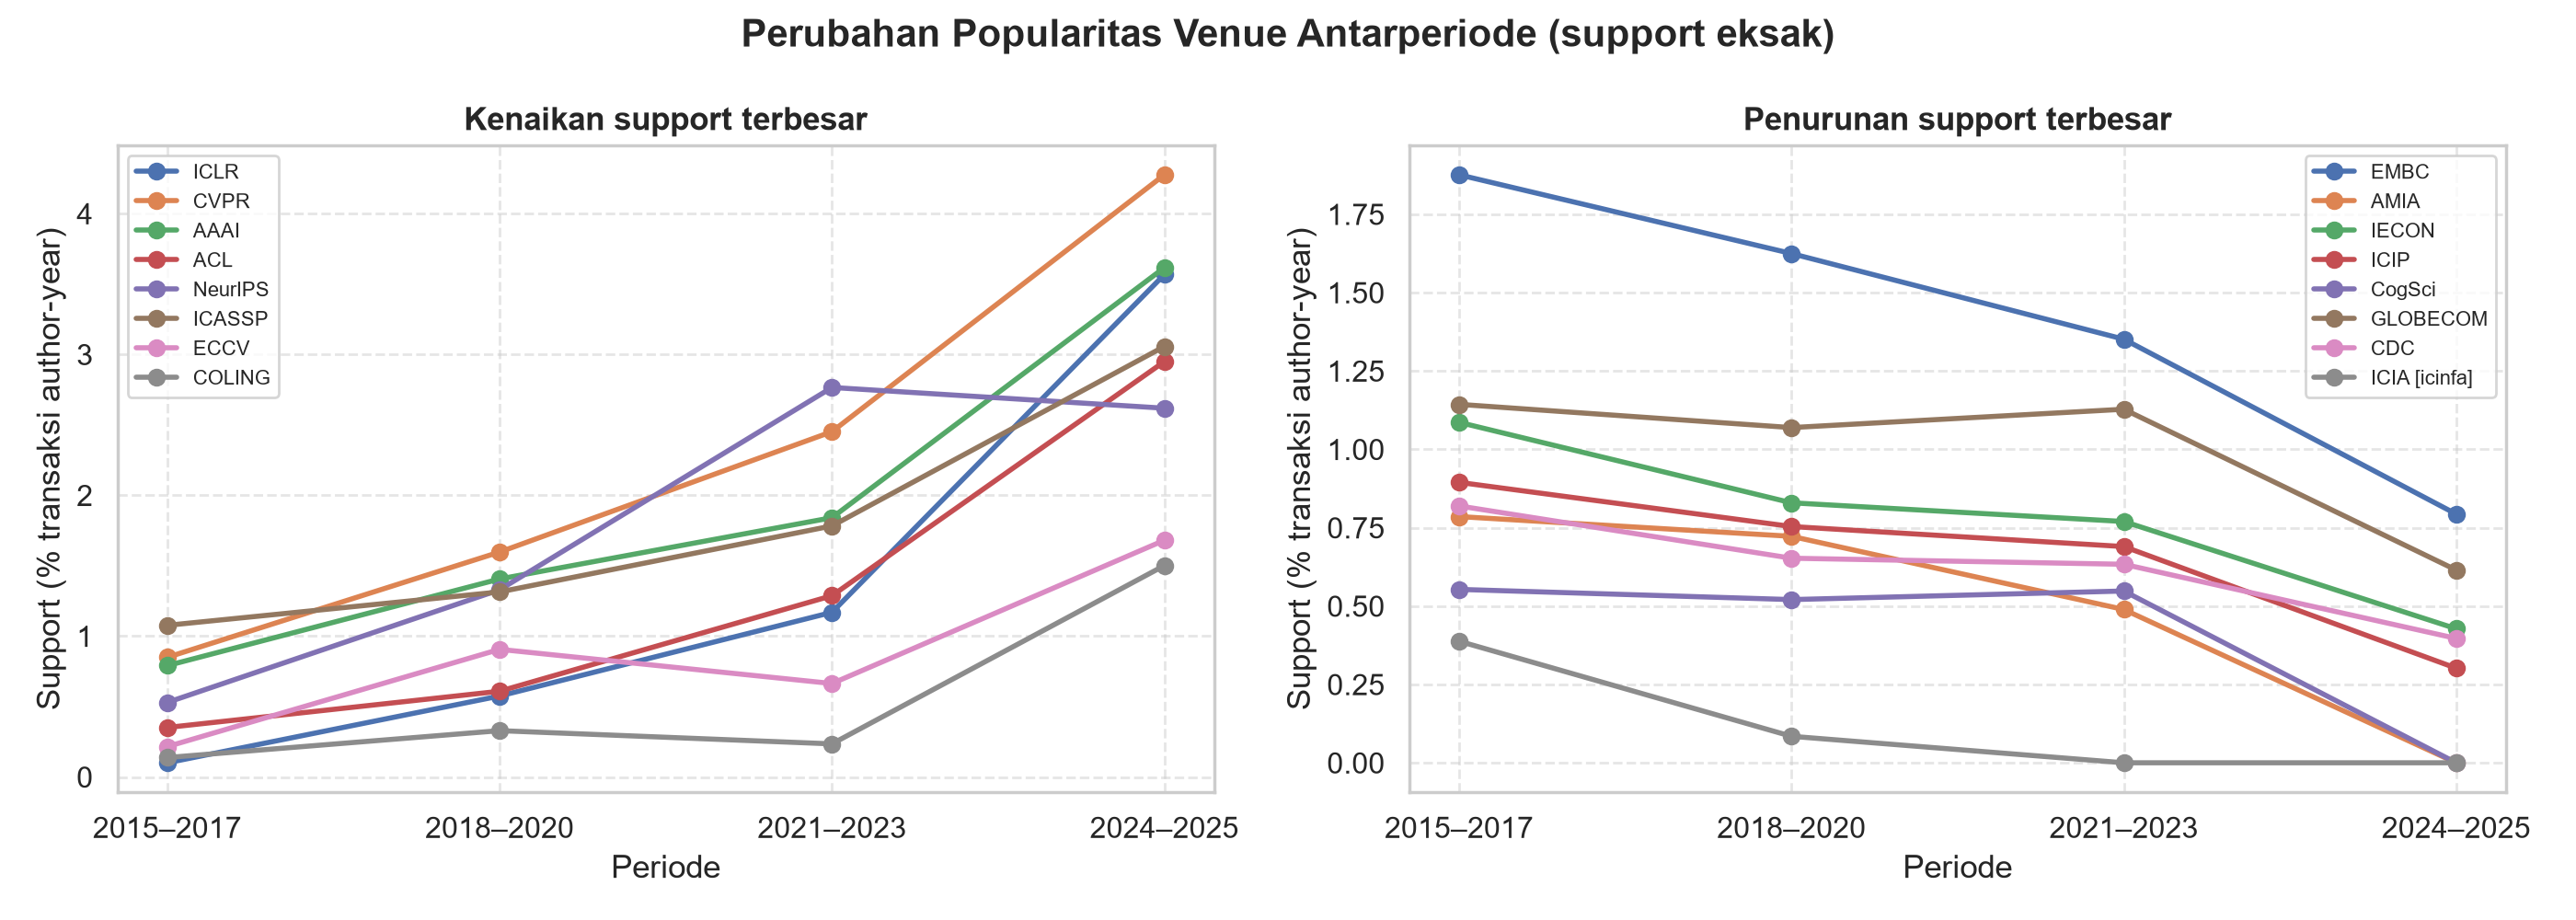

In [18]:
from IPython.display import Image
Image(filename=str(OUTPUT_DIR / 'taskE_venue_support_trend.png'))

### 4.3 Visualisasi Dinamika Asosiasi Lintas Periode

In [19]:
from IPython.display import Image
Image(filename=str(OUTPUT_DIR / 'taskE_temporal_comparison.png'))

FileNotFoundError: [Errno 2] No such file or directory: 'C:\\Users\\rafaa\\ITB\\SEM 7\\Data Mining\\Tubes1\\DataMining_Kelompok11\\output\\role3\\taskE_temporal_comparison.png'

## 5. Jawaban Pertanyaan Evaluasi dan Kesimpulan (Bagian H) (Pertanyaan 5 dan 6)

<!-- **1. Perbedaan pola Author-Based vs Author-Year**
- Jumlah transaksi / % multi-item kedua representasi: ...
- Rule/itemset yang hanya muncul di Author-Based: ...  | hanya di Author-Year: ...
- Catatan konferensi bienial (mis. ICCV/ECCV) yang tidak bisa muncul bersama di Author-Year: ... -->

**2. Pola yang bertahan (`stable_all` / `stable_3`)**
- Rule inti (`taskE_stable_patterns_lift.csv`) dan nilai lift per periode: Berdasarkan hasil eksperimen dapat dilihat bahwa tidak ada pola yang bertahan tiap periodenya.
<!-- - Mengapa stabil (rumpun bidang, komunitas riset): ... -->

**3. Pergeseran tren (`emerging`, `fading`, venue naik/turun)**
- Rule/venue baru setelah 2015-2017 (dari `taskE_shifting_trends.csv`, `taskE_venue_emergence.csv`): 

- Rule/venue yang memudar (dari `taskE_fading_patterns.csv`): ...
- Venue dengan kenaikan/penurunan support terbesar (dari `taskE_venue_support_by_period.csv`):

**4. Keterbatasan**
- Data 2025 belum lengkap (snapshot Desember 2025) sehingga periode 2024-2025 lebih pendek dan datanya lebih sedikit.
- Threshold support relatif (0,08% dari transaksi periode) sehingga jumlah transaksi minimum per periode berbeda.
- Rule absen di suatu periode bisa karena turun di bawah threshold, bukan berarti hilang sepenuhnya.
- Label era (Transformer, LLM, dst.) hanyalah konteks, bukan hasil eksperimen.
